# Simulacion de un portafolio: AAPL, MSFT, NVDA (en pesos), independiente vs correlacionado
### Isaac EMiliano Meza López

## Librerias y parametros

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

np.random.seed(42)

V0 = 100000
M = 10000
T = 1

Importo las librerias, fijo la semilla para que la simulacion me de lo mismo cada vez y pongo lo que invierto (100,000 pesos), el numero de simulaciones y el plazo (1 año).

## 1. Correlaciones AAPL MSFT NVDA

In [18]:
import yfinance as yf
import numpy as np

px = yf.download(["AAPL", "MSFT", "NVDA"], period="3y", auto_adjust=True, progress=False)["Close"].dropna()
print(np.log(px).diff().corr().round(4))


Ticker    AAPL    MSFT    NVDA
Ticker                        
AAPL    1.0000  0.3411  0.2744
MSFT    0.3411  1.0000  0.4098
NVDA    0.2744  0.4098  1.0000


Descargo 3 años de precios de AAPL, MSFT y NVDA y saco la correlacion de sus log rendimientos. Las tres son tecnologicas y si se mueven juntas: MSFT con NVDA 0.41, AAPL con MSFT 0.34 y AAPL con NVDA 0.27. Son mas altas que las de la parte 1, donde la mas alta era 0.21.

## 2. Datos en pesos: mu, sigma y Cholesky

In [19]:
fx = yf.download(['MXN=X'], period='3y')['Close']

precios2 = px.join(fx).ffill().dropna()
rets2 = np.log(precios2 / precios2.shift(1)).dropna()
activos2 = list(rets2.columns)

mu2 = rets2.mean() * 252
sigma2 = rets2.std() * np.sqrt(252)
L2 = np.linalg.cholesky(rets2.cov().values * 252)

S0_2 = {}
for t in activos2:
    S0_2[t] = precios2[t].iloc[-1]

print('mu')
print(mu2)
print()
print('sigma')
print(sigma2)
print()
print('S0')
print(S0_2)

[*********************100%***********************]  1 of 1 completed

mu
Ticker
AAPL     0.223724
MSFT     0.125719
NVDA     0.428316
MXN=X    0.017456
dtype: float64

sigma
Ticker
AAPL     0.268834
MSFT     0.264146
NVDA     0.471193
MXN=X    0.111842
dtype: float64

S0
{'AAPL': 355.6300048828125, 'MSFT': 521.1300048828125, 'NVDA': 173.72999572753906, 'MXN=X': 18.599199295043945}


A los precios de la seccion 1 les pego el tipo de cambio (MXN=X), porque las tres acciones estan en dolares y yo invierto en pesos. Saco los log rendimientos, mu y sigma anuales, y con la matriz de covarianzas anual saco L con Cholesky. Como no nos dieron precios iniciales, uso el ultimo cierre como S0. NVDA es la que mas rinde (42.8%) y la que mas se mueve (47.1%). AAPL rinde 22.4% y MSFT 12.6%, con volatilidades parecidas (cerca de 27%). El tipo de cambio inicial es de 18.60 pesos por dolar.

## 3. Simulacion independiente y correlacionada a T = 1

In [20]:
E2 = np.random.normal(0, 1, [M, 4])
Z2_corr = E2 @ L2.T

ST2_ind = pd.DataFrame()
ST2_corr = pd.DataFrame()
for i in range(4):
    t = activos2[i]
    ST2_ind[t] = S0_2[t] * np.exp(mu2[t] * T + sigma2[t] * np.sqrt(T) * E2[:, i])
    ST2_corr[t] = S0_2[t] * np.exp(mu2[t] * T + np.sqrt(T) * Z2_corr[:, i])

print('Correlacion simulada (correlacionado)')
np.log(ST2_corr / pd.Series(S0_2)).corr().round(3)

Correlacion simulada (correlacionado)


,AAPL,MSFT,NVDA,MXN=X
AAPL,1.000,0.346,0.273,-0.003
MSFT,0.346,1.000,0.406,-0.006
NVDA,0.273,0.406,1.000,0.011
MXN=X,-0.003,-0.006,0.011,1.000


Genero una sola matriz de numeros normales E2 y la uso en los dos casos, para que lo unico que cambie sea la correlacion. En el independiente cada activo usa solo su sigma. En el correlacionado multiplico E2 por L2 transpuesta. Como mu ya viene de log rendimientos, no le resto sigma al cuadrado entre 2. La correlacion simulada sale casi igual a la real: MSFT con NVDA 0.406 (real 0.41), AAPL con MSFT 0.346 (real 0.34) y AAPL con NVDA 0.273 (real 0.27).

## 4. Ni y VT para cada escenario

In [21]:
def resumir(VT_dict):
    return pd.DataFrame({
        'Promedio VT': [VT_dict[e].mean() for e in VT_dict],
        'Desviacion VT': [VT_dict[e].std() for e in VT_dict],
        'VT minimo': [VT_dict[e].min() for e in VT_dict],
        'VT maximo': [VT_dict[e].max() for e in VT_dict],
        'Prob. perder': [(VT_dict[e] < V0).mean() for e in VT_dict],
    }, index=list(VT_dict))

acciones2 = ['AAPL', 'MSFT', 'NVDA']

escenarios2 = {
    '1': [1, 0, 0],
    '2': [0.33, 0.33, 0.34],
    '3': [0.2, 0.2, 0.6],
}

N2 = {}
for e in escenarios2:
    N2[e] = {}
    for i in range(3):
        accion = acciones2[i]
        N2[e][accion] = escenarios2[e][i] * V0 / (S0_2[accion] * S0_2['MXN=X'])

VT2_ind = {}
VT2_corr = {}
for e in escenarios2:
    VT2_ind[e] = 0
    VT2_corr[e] = 0
    for accion in acciones2:
        VT2_ind[e] = VT2_ind[e] + N2[e][accion] * ST2_ind[accion] * ST2_ind['MXN=X']
        VT2_corr[e] = VT2_corr[e] + N2[e][accion] * ST2_corr[accion] * ST2_corr['MXN=X']

print(pd.DataFrame(N2))
pd.concat([resumir(VT2_ind), resumir(VT2_corr)], keys=['independiente', 'correlacionado']).round(2)

              1          2          3
AAPL  15.118453   4.989090   3.023691
MSFT   0.000000   3.404659   2.063430
NVDA   0.000000  10.522280  18.568730


Promedio VT  Desviacion VT  VT minimo  VT maximo  \
independiente  1    133024.08       39434.48   41483.20  391498.40   
               2    143133.47       37904.41   55191.44  403312.81   
               3    155878.24       57076.21   50831.43  581965.78   
correlacionado 1    133072.98       39610.90   41141.64  393711.81   
               2    143097.66       44168.40   41160.02  471058.56   
               3    155784.92       60991.00   37075.18  696380.07   

                  Prob. perder  
independiente  1          0.20  
               2          0.09  
               3          0.12  
correlacionado 1          0.20  
               2          0.14  
               3          0.15

Calculo cuantas acciones compro de cada una (Ni) con los 100,000 pesos, pasando su precio a pesos con el tipo de cambio; por ejemplo, en el escenario 1 compro 15.12 acciones de AAPL y en el 3 compro 18.57 de NVDA. Luego calculo VT con los precios y el tipo de cambio simulados, en los dos casos. En la tabla se ve que el promedio no cambia (1: 133,024 contra 133,073; 2: 143,133 contra 143,098; 3: 155,878 contra 155,785). En el escenario 1 todo queda igual, con 20% de probabilidad de perder. En el 2 la desviacion sube de 37,904 a 44,168 (17% mas) y la probabilidad de perder pasa de 9% a 14%, y en el 3 la desviacion sube de 57,076 a 60,991 (7% mas) y la probabilidad de perder pasa de 12% a 15%.

## 5. Graficas independiente vs correlacionado

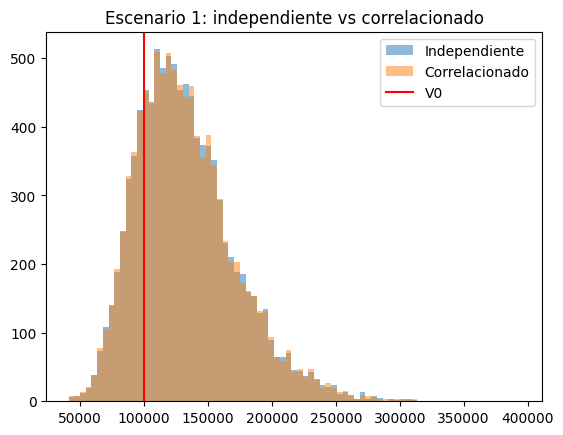

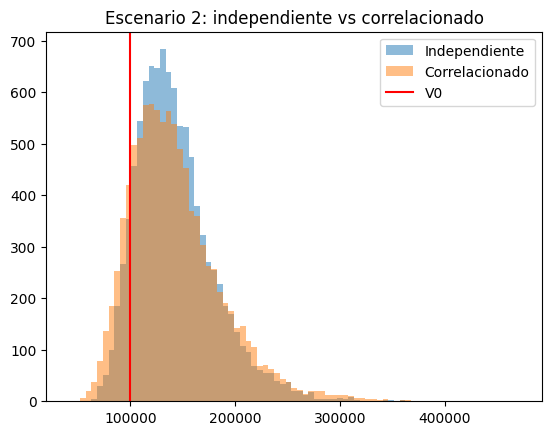

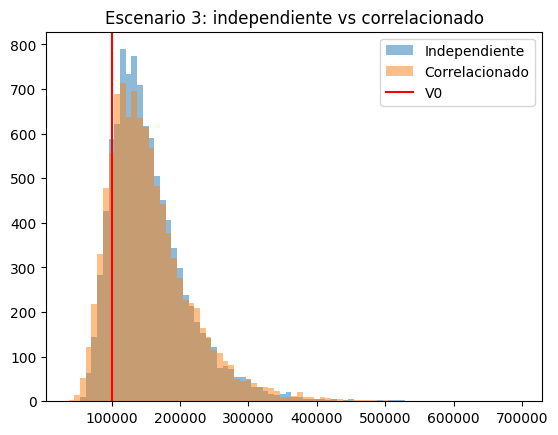

In [22]:
def comparar_ind_corr(v_ind, v_corr, titulo):
    bins = np.linspace(min(v_ind.min(), v_corr.min()), max(v_ind.max(), v_corr.max()), 80)
    plt.hist(v_ind, bins=bins, alpha=0.5, label='Independiente')
    plt.hist(v_corr, bins=bins, alpha=0.5, label='Correlacionado')
    plt.axvline(V0, color='red', label='V0')
    plt.title(titulo)
    plt.legend()
    plt.show()

for e in escenarios2:
    comparar_ind_corr(VT2_ind[e], VT2_corr[e], 'Escenario ' + e + ': independiente vs correlacionado')

Para cada escenario dibujo los dos histogramas uno encima del otro con los mismos bins. La linea roja es lo que inverti. En el escenario 1 las dos distribuciones son iguales. En el 2 y el 3 la correlacionada es mas ancha: llega mas abajo (el minimo baja de 55,191 a 41,160 en el escenario 2) y tambien mas arriba.

## 6. VaR y CVaR

In [23]:
def var_cvar(v, nivel):
    corte = np.percentile(v, (1 - nivel) * 100)
    VaR = V0 - corte
    CVaR = V0 - v[v <= corte].mean()
    return VaR, CVaR

filas = []
nombres = []
for e in escenarios2:
    for caso in ['independiente', 'correlacionado']:
        if caso == 'independiente':
            v = VT2_ind[e]
        else:
            v = VT2_corr[e]
        var95, cvar95 = var_cvar(v, 0.95)
        var99, cvar99 = var_cvar(v, 0.99)
        nombres.append(e + ' ' + caso)
        filas.append([var95, cvar95, var99, cvar99])

pd.DataFrame(filas, index=nombres, columns=['VaR 95%', 'CVaR 95%', 'VaR 99%', 'CVaR 99%']).round(2)

,VaR 95%,CVaR 95%,VaR 99%,CVaR 99%
1 independiente,20871.00,29923.02,35767.06,42139.56
1 correlacionado,20977.86,30107.30,35994.09,42342.45
2 independiente,6766.56,14704.82,19915.98,25101.93
2 correlacionado,14473.70,23256.62,28783.73,35001.63
3 independiente,12808.16,21613.40,27492.66,32731.60
3 correlacionado,18600.12,28334.69,34484.02,40834.39


El VaR es lo que puedo perder con 95% (o 99%) de confianza: V0 menos el percentil 5 (o 1) de VT. El CVaR es lo que pierdo en promedio en ese 5% (o 1%) de peores casos, por eso siempre es mas grande que el VaR. En el escenario 1 casi no cambia (VaR 95% de 20,871 contra 20,978). En el 2 el VaR 95% se duplica, de 6,767 a 14,474, y el CVaR 95% pasa de 14,705 a 23,257. En el 3 el VaR 95% sube de 12,808 a 18,600 y el CVaR 95% de 21,613 a 28,335, y al 99% pasa lo mismo. Con independencia el escenario 2 parecia por mucho el menos riesgoso; con correlacion sigue siendo el de menor VaR, pero la diferencia con los otros es mucho mas chica.

## 7. Distribuciones con Q1, mu, Q2 y Q3

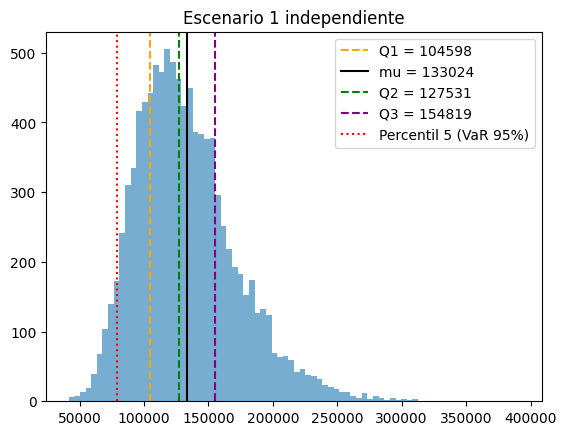

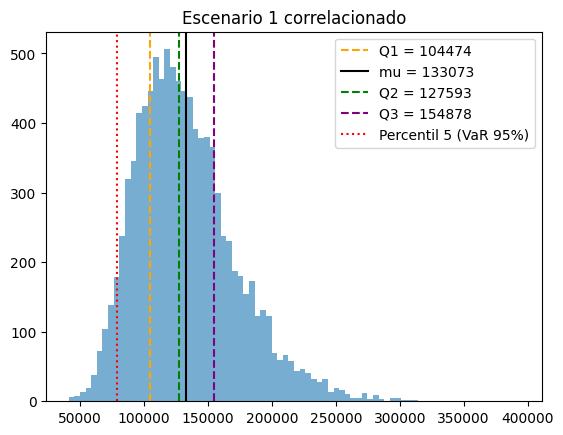

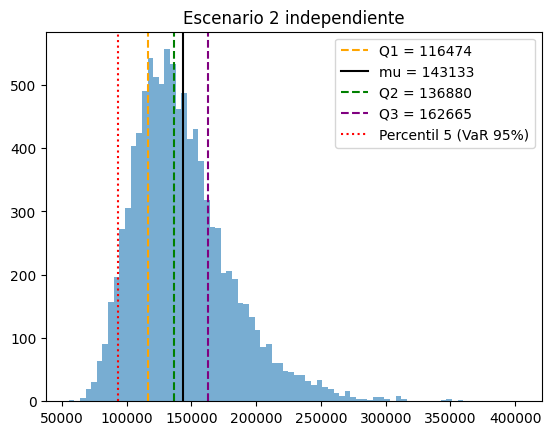

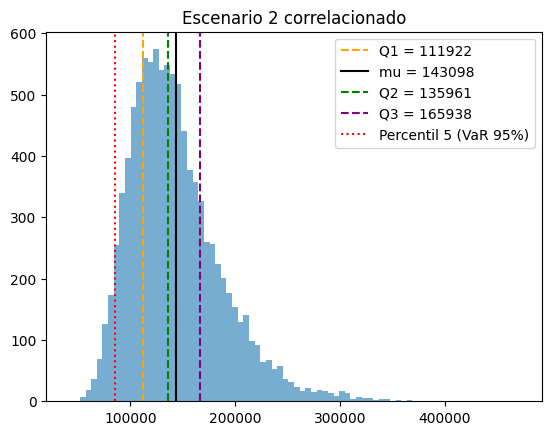

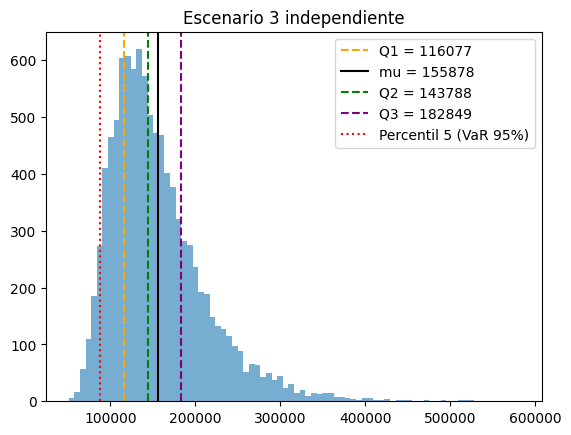

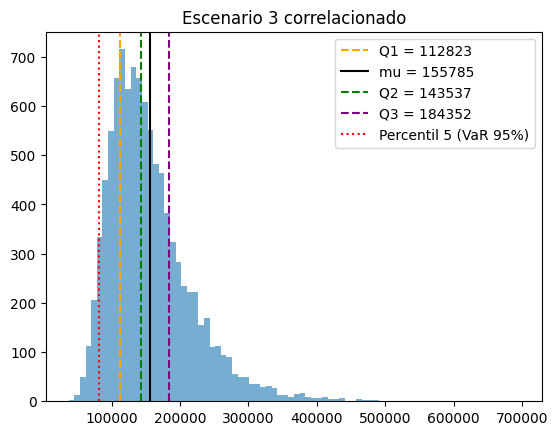

In [24]:
def graficar_cuartiles(v, titulo):
    Q1 = np.percentile(v, 25)
    Q2 = np.percentile(v, 50)
    Q3 = np.percentile(v, 75)
    media = v.mean()

    plt.hist(v, bins=80, alpha=0.6)
    plt.axvline(Q1, color='orange', linestyle='--', label='Q1 = ' + str(round(Q1)))
    plt.axvline(media, color='black', label='mu = ' + str(round(media)))
    plt.axvline(Q2, color='green', linestyle='--', label='Q2 = ' + str(round(Q2)))
    plt.axvline(Q3, color='purple', linestyle='--', label='Q3 = ' + str(round(Q3)))
    plt.axvline(np.percentile(v, 5), color='red', linestyle=':', label='Percentil 5 (VaR 95%)')
    plt.title(titulo)
    plt.legend()
    plt.show()

for e in escenarios2:
    graficar_cuartiles(VT2_ind[e], 'Escenario ' + e + ' independiente')
    graficar_cuartiles(VT2_corr[e], 'Escenario ' + e + ' correlacionado')

Para cada escenario dibujo la distribucion de VT con lineas en Q1, mu, Q2 (mediana) y Q3, y marco el percentil 5, que es el corte del VaR 95%. En todos los casos mu queda a la derecha de Q2 (por ejemplo, en el escenario 3 correlacionado mu = 155,785 y Q2 = 143,537), porque la distribucion esta cargada a la derecha y unos pocos casos con ganancias muy grandes suben el promedio pero no la mediana. Con correlacion Q1 baja y Q3 sube: en el escenario 2, Q1 pasa de 116,474 a 111,922 y Q3 de 162,665 a 165,938, o sea que la mitad central de los resultados queda mas abierta, mientras que en el escenario 1 los cuartiles casi no cambian. Q1 queda arriba de 100,000 en todos los casos, asi que en mas del 75% de las simulaciones gano dinero.

## 8. Conclusiones

La correlacion no cambia lo que espero ganar, porque el promedio de VT es practicamente el mismo en los dos casos, pero si cambia el riesgo. El escenario 1 (todo en AAPL) no cambia porque solo depende de una accion y del tipo de cambio. El escenario 2, con pesos casi iguales, es el que mas cambia: la desviacion sube 17%, la probabilidad de perder pasa de 9% a 14% y el VaR 95% se duplica, porque es el que mas depende de que las acciones no se muevan juntas. El escenario 3 cambia menos (la desviacion sube 7%) porque el 60% esta en NVDA y el riesgo lo pone casi todo una sola accion. El efecto es mas fuerte que en la parte 1 (alla B subio 11% y aqui el escenario 2 sube 17%), porque AAPL, MSFT y NVDA son del mismo sector y estan mas correlacionadas. Ademas, la distribucion de VT esta cargada a la derecha (mu mayor que Q2) y el CVaR siempre sale mayor que el VaR. En resumen, si supongo que las acciones son independientes subestimo el riesgo del portafolio, sobre todo cuando reparto el dinero entre acciones que se mueven juntas.